# Acousto-optics: Bragg diffraction by sound, modulators, deflectors and tunable filters

A sound wave in a crystal or a glass compresses and stretches it
periodically, and the photoelastic effect turns the strain into an index
grating: $\Delta n\sin(Kx - \Omega t)$ with the acoustic wave number
$K = 2\pi/\Lambda$ and $\Lambda = v/f$, tens of micrometres at tens of MHz.
Light crossing the sound column is diffracted by this moving grating. The
diffracted light is shifted in frequency by $f$ (the grating moves),
appears and disappears with the radio frequency drive within
microseconds, leaves at an angle proportional to $f$, and in a
birefringent crystal it is diffracted only in a narrow band of
wavelengths. These are the four acousto-optic devices: the frequency
shifter, the modulator (AOM), the deflector (AOD) and the tunable filter
(AOTF).

This notebook uses the `acoustooptics` module:

1. Raman–Nath against Bragg diffraction: the Klein–Cook parameter and the
   coupled wave equations,
2. Bragg efficiency against acoustic power, the figure of merit of the
   materials,
3. the AOM: angular acceptance, rise time and frequency shift,
4. the AOD: deflection, bandwidth and resolvable spots,
5. the AOTF: tuning, passband and side lobes.

The tunable filter of notebook 122 (imaging spectroscopy) uses section 5.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import acoustooptics as ao
from pyoptics import spectroscopy as spc
from pyoptics import sketch

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

## 1. Raman–Nath against Bragg diffraction

Two numbers describe the interaction. The **Raman–Nath parameter**
$\nu = 2\pi\Delta n L/\lambda$ is the peak phase modulation that the
light picks up over the transducer length $L$. The **Klein–Cook
parameter** $Q = 2\pi\lambda L/(n\Lambda^2) = K^2L/k$ compares $L$ with
the length over which a diffracted wave walks out of step with the
grating. For $Q \ll 1$ the sound column is a thin phase grating and the
light is diffracted into many orders with the powers $J_m(\nu)^2$
(Raman–Nath). For $Q \gg 1$ the column is a thick grating: only light
incident at the Bragg angle $\theta_B = \lambda/(2n\Lambda)$ is diffracted,
into one order, with the efficiency $\sin^2(\nu/2)$. In between, the
paraxial coupled wave equations for the order amplitudes $E_m(\zeta)$,
$\zeta = z/L$,

$$\frac{dE_m}{d\zeta} = \frac\nu2\,(E_{m-1} - E_{m+1}) - i\frac Q2\,m(m - \alpha)E_m,$$

with the angle of incidence $\alpha\theta_B$, have constant coefficients
and are solved by a matrix exponential (`ao.coupled_orders()`).

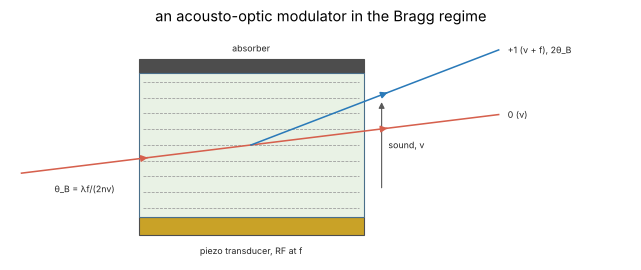

In [2]:
fig, ax = plt.subplots(figsize=(11, 3.8))
sketch.modulator_layout(ax, "aom", title="an acousto-optic modulator in the Bragg regime")
plt.show()

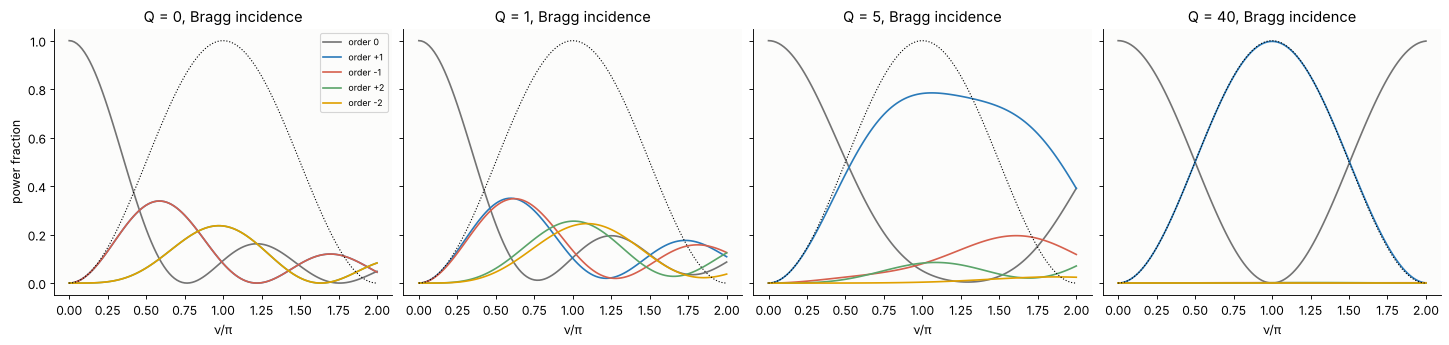

Q =    1: at ν = π the order +1 carries 0.102, the others 0.898
Q =    5: at ν = π the order +1 carries 0.782, the others 0.218
Q =   10: at ν = π the order +1 carries 0.937, the others 0.063
Q =   40: at ν = π the order +1 carries 0.997, the others 0.003


In [3]:
nu = np.linspace(0, 2*np.pi, 121)
fig, ax = plt.subplots(1, 4, figsize=(18, 4.2), layout="constrained", sharey=True)
for a, Q in zip(ax, (0.0, 1.0, 5.0, 40.0)):
    P = np.array([np.abs(ao.coupled_orders(v, Q, alpha=1.0)[1])**2 for v in nu])
    m = ao.coupled_orders(0.1, Q)[0]
    for order, c in ((0, GREY), (1, BLUE), (-1, RED), (2, GREEN), (-2, ORANGE)):
        a.plot(nu/np.pi, P[:, m == order], color=c, label=f"order {order:+d}" if order else "order 0")
    a.plot(nu/np.pi, np.sin(nu/2)**2, "k:", lw=1)
    a.set_title(f"Q = {Q:g}, Bragg incidence"); a.set_xlabel("ν/π")
ax[0].set_ylabel("power fraction"); ax[0].legend(fontsize=8)
plt.show()
for Q in (1.0, 5.0, 10.0, 40.0):
    m, E = ao.coupled_orders(np.pi, Q, alpha=1.0)
    print("Q = {:4.0f}: at ν = π the order +1 carries {:.3f}, the others {:.3f}".format(Q, abs(E[m == 1][0])**2, 1 - abs(E[m == 1][0])**2))

The dotted line is the two-wave Bragg result $\sin^2(\nu/2)$. At $Q = 0$
the light spreads symmetrically over many orders (here incident at
the Bragg angle, which does not matter for a thin grating); at $Q = 5$ the
order +1 already dominates but reaches only 78 % at $\nu = \pi$; at
$Q = 10$ it gets 94 % and at $Q = 40$ more than 99 %, a clean Bragg cell. Practical AOMs work at $Q$ of 10 to 100.

## 2. Efficiency and the acoustic figure of merit

The index amplitude for an acoustic intensity $I_a = P/(LH)$ (transducer
length $L$, height $H$) is $\Delta n = \sqrt{M_2I_a/2}$ with the figure of
merit $M_2 = n^6p^2/(\rho v^3)$ (photoelastic constant $p$, density
$\rho$), so the Bragg efficiency is

$$\eta = \sin^2\left(\frac{\pi}{\sqrt2\,\lambda}\sqrt{\frac{M_2LP}{H}}\right).$$

The drive power for full efficiency grows as $\lambda^2$ and falls with
$M_2$: slow, dense, high index materials win. TeO₂ in its slow shear mode
(617 m/s) has the largest $M_2$ of the common crystals, but that mode is
used for deflectors and filters (sections 4, 5); modulators use the
longitudinal mode of TeO₂ or fused silica for high power lasers.

material              v (m/s)  M2 (e-15)  P(100 %) 633 nm P(100 %) 1064 nm
fused silica             5960        1.5           6.63 W          18.74 W
TeO2 longitudinal        4200       34.5           0.29 W           0.82 W
TeO2 shear                617      793.0           0.01 W           0.04 W
PbMoO4                   3630       36.3           0.28 W           0.78 W
Ge (10.6 µm)             5500      180.0                  15.6 W (10.6 µm)


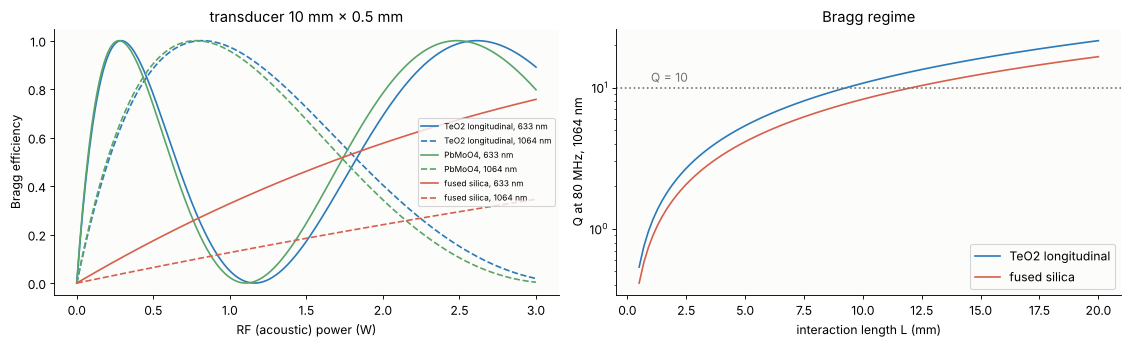

In [4]:
L_t, H_t = 10e-3, 0.5e-3                              # transducer 10 mm long, 0.5 mm high
print("{:20s} {:>8s} {:>10s} {:>16s} {:>16s}".format("material", "v (m/s)", "M2 (e-15)", "P(100 %) 633 nm", "P(100 %) 1064 nm"))
for name, m in ao.MATERIALS.items():
    if "Ge" in name:
        lams = (10.6e-6,)
    else:
        lams = (633e-9, 1064e-9)
    Pf = [l**2*H_t/(2*m["M2"]*L_t) for l in lams]
    print("{:20s} {:8.0f} {:10.1f} {:>16s} {:>16s}".format(name, m["v"], m["M2"]*1e15,
          *(["{:.2f} W".format(p) for p in Pf] if len(Pf) == 2 else ["", "{:.1f} W (10.6 µm)".format(Pf[0])])))
P = np.linspace(0, 3, 301)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), layout="constrained")
for name, c in (("TeO2 longitudinal", BLUE), ("PbMoO4", GREEN), ("fused silica", RED)):
    m = ao.MATERIALS[name]
    for lam_, ls in ((633e-9, "-"), (1064e-9, "--")):
        dn = ao.delta_n_from_power(P, m["M2"], L_t, H_t)
        ax[0].plot(P, ao.bragg_efficiency(ao.raman_nath_parameter(dn, L_t, lam_)), color=c, ls=ls,
                   label=f"{name}, {lam_*1e9:.0f} nm")
ax[0].set_xlabel("RF (acoustic) power (W)"); ax[0].set_ylabel("Bragg efficiency"); ax[0].legend(fontsize=7.5)
ax[0].set_title("transducer 10 mm × 0.5 mm")
f = 80e6
for name, c in (("TeO2 longitudinal", BLUE), ("fused silica", RED)):
    m = ao.MATERIALS[name]
    Ls = np.linspace(0.5e-3, 20e-3, 100)
    ax[1].plot(Ls*1e3, ao.klein_cook_q(1064e-9, m["n"], m["v"]/f, Ls), color=c, label=name)
ax[1].axhline(10, color=GREY, ls=":"); ax[1].text(1, 11, "Q = 10", color=GREY)
ax[1].set_xlabel("interaction length L (mm)"); ax[1].set_ylabel("Q at 80 MHz, 1064 nm"); ax[1].legend()
ax[1].set_yscale("log"); ax[1].set_title("Bragg regime")
plt.show()

With a 10 mm × 0.5 mm transducer the longitudinal TeO₂ modulator reaches
100 % at 1064 nm with 0.8 W of acoustic power, fused silica needs 19 W,
which is why silica AOMs are long or used as Q-switches with a partial
efficiency, and germanium at 10.6 µm (CO₂ lasers) needs 16 W despite its
large $M_2$, because of the $\lambda^2$. Transducers convert RF to sound
with 50 to 80 % efficiency, so the RF power is larger still. At 80 MHz the
TeO₂ cell is in the Bragg regime for $L > 9$ mm, fused silica (faster
sound, longer $\Lambda$) only for $L > 12$ mm: short silica cells at low
frequencies are partly Raman–Nath cells, with light in several orders.

## 3. The AOM: angular acceptance, rise time, frequency shift

**Angular acceptance.** Off the Bragg angle the diffracted wave is out of
phase with the grating; the efficiency falls over an angular range of
about $\Lambda/L$, the divergence of the sound beam. For a focused laser
beam this is the condition that the beam divergence stays below the
sound divergence. **Speed.** The modulator switches when the sound has
crossed the light beam: a rise time of $0.64\,D/v$ for a Gaussian beam of
diameter $D$, so the beam is focused into the AOM, as far as the angular
acceptance allows. **Frequency shift.** The order +1 is shifted up by $f$,
the order −1 down: AOMs are the frequency shifters of heterodyne
interferometers, laser Doppler vibrometers and the cooling lasers of
atomic physics.

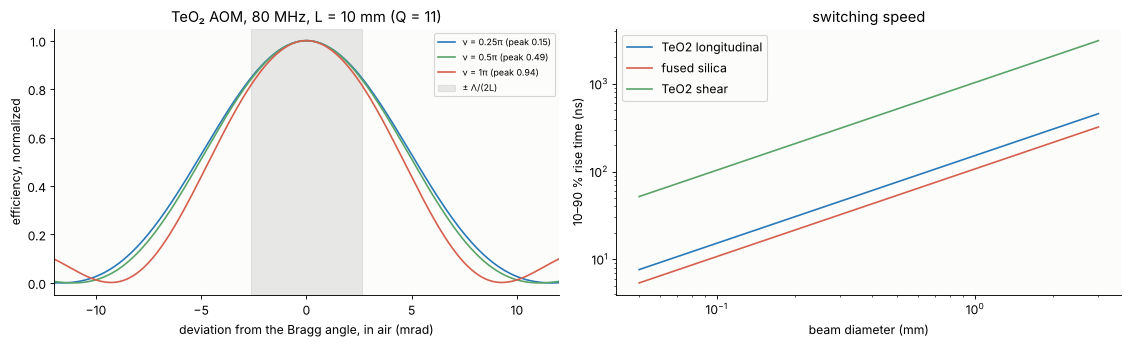

Bragg angle in air 10.13 mrad, Λ = 52.5 µm, Λ/L = 5.2 mrad
rise time, TeO2 longitudinal: 152 ns for a 1 mm beam, 15 ns for 100 µm


In [5]:
lam = 1064e-9
m = ao.MATERIALS["TeO2 longitudinal"]
Lam = m["v"]/f
theta_B = lam/(2*m["n"]*Lam)
Q = ao.klein_cook_q(lam, m["n"], Lam, L_t)
alpha = np.linspace(-1, 3, 401)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), layout="constrained")
for nu_, c in ((np.pi/4, BLUE), (np.pi/2, GREEN), (np.pi, RED)):
    eta = [abs(ao.coupled_orders(nu_, Q, a_)[1][ao.coupled_orders(nu_, Q, a_)[0] == 1][0])**2 for a_ in alpha]
    ax[0].plot((alpha - 1)*theta_B*1e3*m["n"], np.array(eta)/max(eta), color=c, label=f"ν = {nu_/np.pi:.2g}π (peak {max(eta):.2f})")
ax[0].axvspan(-0.5*Lam/L_t*1e3, 0.5*Lam/L_t*1e3, color=GREY, alpha=0.15, label="± Λ/(2L)")
ax[0].set_xlim(-12, 12)
ax[0].set_xlabel("deviation from the Bragg angle, in air (mrad)"); ax[0].set_ylabel("efficiency, normalized")
ax[0].legend(fontsize=8); ax[0].set_title(f"TeO₂ AOM, 80 MHz, L = 10 mm (Q = {Q:.0f})")
D = np.linspace(0.05, 3, 100)*1e-3
for name, c in (("TeO2 longitudinal", BLUE), ("fused silica", RED), ("TeO2 shear", GREEN)):
    ax[1].loglog(D*1e3, ao.aom_rise_time(D, ao.MATERIALS[name]["v"])*1e9, color=c, label=name)
ax[1].set_xlabel("beam diameter (mm)"); ax[1].set_ylabel("10–90 % rise time (ns)"); ax[1].legend()
ax[1].set_title("switching speed")
plt.show()
print("Bragg angle in air {:.2f} mrad, Λ = {:.1f} µm, Λ/L = {:.1f} mrad".format(theta_B*m["n"]*1e3, Lam*1e6, Lam/L_t*1e3))
print("rise time, TeO2 longitudinal: {:.0f} ns for a 1 mm beam, {:.0f} ns for 100 µm".format(
    ao.aom_rise_time(1e-3, m["v"])*1e9, ao.aom_rise_time(1e-4, m["v"])*1e9))

The efficiency falls to half within about ±4.5 mrad (in air) of the Bragg angle
(10 mrad in air for 80 MHz at 1064 nm), close to the sound divergence
$\Lambda/L = 5.2$ mrad; at full drive ($\nu = \pi$) the acceptance curve is
narrower and develops shoulders, because the light is diffracted back
into the order 0 inside the cell. A beam focused to 100 µm switches in 15 ns
in longitudinal TeO₂ and has a divergence of 13 mrad, larger than the
acceptance: fast AOMs trade efficiency for speed. The shear mode of TeO₂,
seven times slower, is useless for fast switching but ideal for the next
device.

## 4. The AOD: deflection and resolvable spots

Changing the frequency changes the grating period and hence the angle of
the diffracted beam, $\lambda f/v$ in air. The number of distinct spots
it can address is the deflection range divided by the beam divergence
$\lambda/D$: $N = (D/v)\Delta f = \tau\Delta f$, the product of the access
time $\tau$ (the sound crossing the aperture) and the bandwidth. Slow sound
gives many spots but a long access time. The bandwidth is limited by the
transducer and by the Bragg condition: at a fixed angle of incidence, set
for the centre frequency, the mismatch grows towards the band edges.

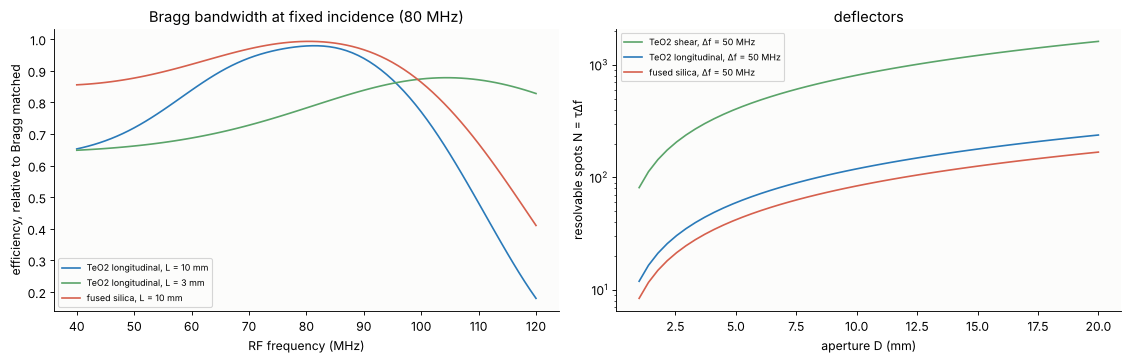

TeO2 shear: 10 mm aperture: access time 16.2 µs, 810 spots over 50 MHz, scan range 86.2 mrad at 1064 nm
TeO2 longitudinal: 10 mm aperture: access time 2.4 µs, 119 spots over 50 MHz, scan range 12.7 mrad at 1064 nm


In [6]:
fc_ = 80e6
fs = np.linspace(40e6, 120e6, 81)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4), layout="constrained")
for name, Ld, c in (("TeO2 longitudinal", 10e-3, BLUE), ("TeO2 longitudinal", 3e-3, GREEN), ("fused silica", 10e-3, RED)):
    mm = ao.MATERIALS[name]
    eff = []
    for f_ in fs:
        Lam_ = mm["v"]/f_
        Qf = ao.klein_cook_q(lam, mm["n"], Lam_, Ld)
        # the incidence is fixed at the Bragg angle of the centre frequency: alpha = f_c/f
        dn = ao.delta_n_from_power(1.0, mm["M2"], Ld, H_t)
        nu_f = min(ao.raman_nath_parameter(dn, Ld, lam), np.pi/2)
        mo, E = ao.coupled_orders(nu_f, Qf, alpha=fc_/f_)
        eff.append(abs(E[mo == 1][0])**2/np.sin(nu_f/2)**2)
    ax[0].plot(fs/1e6, eff, color=c, label=f"{name}, L = {Ld*1e3:.0f} mm")
ax[0].set_xlabel("RF frequency (MHz)"); ax[0].set_ylabel("efficiency, relative to Bragg matched")
ax[0].legend(fontsize=8); ax[0].set_title("Bragg bandwidth at fixed incidence (80 MHz)")
Dap = np.linspace(1, 20, 50)*1e-3
for name, bw, c in (("TeO2 shear", 50e6, GREEN), ("TeO2 longitudinal", 50e6, BLUE), ("fused silica", 50e6, RED)):
    v = ao.MATERIALS[name]["v"]
    ax[1].plot(Dap*1e3, ao.aod_spots(Dap, v, bw), color=c, label=f"{name}, Δf = 50 MHz")
ax[1].set_xlabel("aperture D (mm)"); ax[1].set_ylabel("resolvable spots N = τΔf"); ax[1].legend(fontsize=8)
ax[1].set_yscale("log"); ax[1].set_title("deflectors")
plt.show()
for name in ("TeO2 shear", "TeO2 longitudinal"):
    v = ao.MATERIALS[name]["v"]
    print("{}: 10 mm aperture: access time {:.1f} µs, {:.0f} spots over 50 MHz, scan range {:.1f} mrad at 1064 nm".format(
        name, 10e-3/v*1e6, ao.aod_spots(10e-3, v, 50e6), ao.aod_deflection(lam, 50e6, v)*1e3))

An isotropic Bragg cell set for 80 MHz keeps half of its efficiency only
over ±10 MHz when it is 10 mm long; a 3 mm cell has a wide band but a $Q$
near the Raman–Nath regime, and loses light into other orders. Real
deflectors avoid the dilemma with **anisotropic** Bragg diffraction in
TeO₂: the diffracted light changes polarization and index, and in the
"tangential" geometry the momentum mismatch stays small over an octave of
frequency. A 10 mm TeO₂ shear wave AOD with 50 MHz of bandwidth resolves
810 spots with an access time of 16 µs; the same aperture in longitudinal
TeO₂ resolves only 119 spots but switches in 2.4 µs. AODs steer the beams
of laser scanning microscopes, optical tweezers arrays and the atom
arrays of neutral atom quantum computers.

## 5. The AOTF

In a birefringent crystal the incident and diffracted waves can have
different polarizations and indices (o in, e out). The momentum match
then depends strongly on the wavelength: for a given acoustic frequency
only a narrow band is diffracted, rotated in polarization and deviated by
a few degrees, where it can be separated from the white light. In Chang's
non-collinear TeO₂ geometry, with the light at $\theta_i$ to the optic
axis and the slow shear wave chosen so that the tangents of the index
surfaces are parallel (a large angular aperture), the tuning relation is

$$f = \frac{v\,\Delta n}{\lambda}\sqrt{\sin^4\theta_i + \sin^2 2\theta_i},$$

and the passband FWHM is
$1.8\pi\lambda^2/(bL\sin^2\theta_i)$, $b = 2\pi(\Delta n - \lambda\,\partial\Delta n/\partial\lambda)$.
`ao.aotf_transmission()` models the passband as a two-wave Bragg
interaction with the corresponding momentum mismatch.

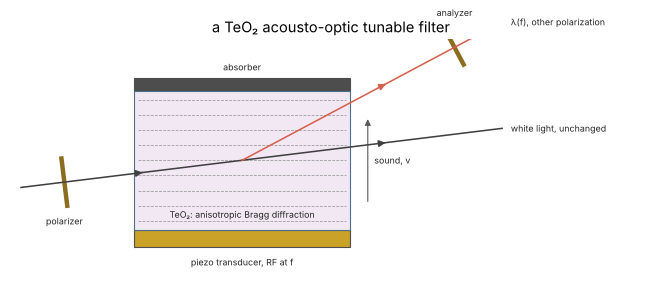

In [7]:
fig, ax = plt.subplots(figsize=(12, 3.8))
sketch.modulator_layout(ax, "aotf", title="a TeO₂ acousto-optic tunable filter")
plt.show()

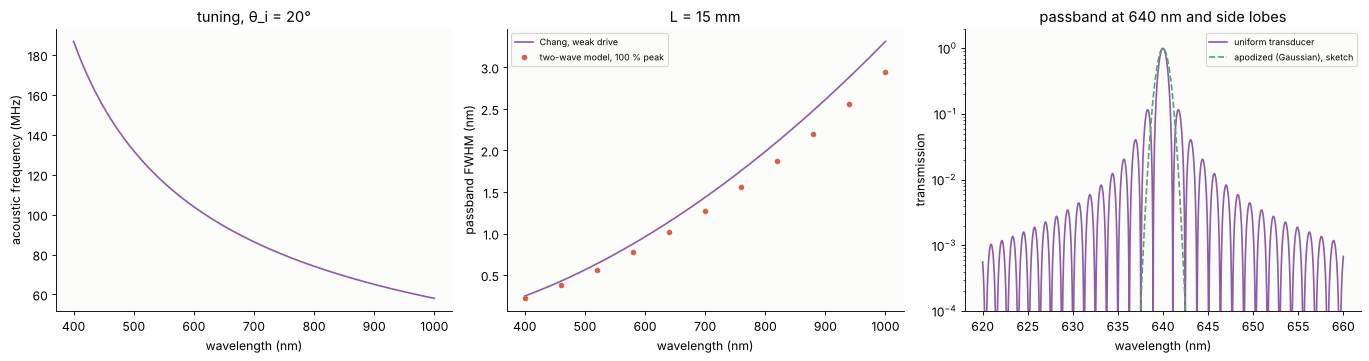

450 nm: f = 153.9 MHz, FWHM 0.39 nm
640 nm: f = 96.0 MHz, FWHM 1.14 nm
900 nm: f = 65.1 MHz, FWHM 2.61 nm
first side lobe -9.3 dB below the peak


In [8]:
dn_teo2 = lambda l: np.subtract(*ao.teo2_indices(np.asarray(l)*1e9)[::-1])
v_s = ao.MATERIALS["TeO2 shear"]["v"]
th_i = np.radians(20.0)
L_f = 15e-3
lam_t = np.linspace(400e-9, 1000e-9, 301)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4), layout="constrained")
ax[0].plot(lam_t*1e9, ao.aotf_frequency(lam_t, dn_teo2(lam_t), v_s, th_i)/1e6, color=PURPLE)
ax[0].set_xlabel("wavelength (nm)"); ax[0].set_ylabel("acoustic frequency (MHz)"); ax[0].set_title("tuning, θ_i = 20°")
ax[1].plot(lam_t*1e9, ao.aotf_passband(lam_t, L_f, th_i, dn_teo2)*1e9, color=PURPLE, label="Chang, weak drive")
fw = []
for l0 in lam_t[::30]:
    ll = np.linspace(l0 - 15e-9, l0 + 15e-9, 6001)
    T = ao.aotf_transmission(ll, l0, L_f, th_i, dn_teo2)
    fw.append(spc.fwhm(ll, T))
ax[1].plot(lam_t[::30]*1e9, np.array(fw)*1e9, "o", color=RED, ms=4, label="two-wave model, 100 % peak")
ax[1].set_xlabel("wavelength (nm)"); ax[1].set_ylabel("passband FWHM (nm)"); ax[1].legend(fontsize=8)
ax[1].set_title(f"L = {L_f*1e3:.0f} mm")
ll = np.linspace(620e-9, 660e-9, 8001)
T = ao.aotf_transmission(ll, 640e-9, L_f, th_i, dn_teo2)
ax[2].semilogy(ll*1e9, np.maximum(T, 1e-6), color=PURPLE, label="uniform transducer")
# apodized (Gaussian weighted) transducer: the passband of a Gaussian coupling profile is near Gaussian
sig = spc.fwhm(ll, T)/2.355
ax[2].semilogy(ll*1e9, np.maximum(np.exp(-0.5*((ll - 640e-9)/(1.35*sig))**2), 1e-6), color=GREEN, ls="--",
               label="apodized (Gaussian), sketch")
ax[2].set_ylim(1e-4, 2); ax[2].set_xlabel("wavelength (nm)"); ax[2].set_ylabel("transmission")
ax[2].legend(fontsize=8); ax[2].set_title("passband at 640 nm and side lobes")
plt.show()
for l0 in (450e-9, 640e-9, 900e-9):
    print("{:.0f} nm: f = {:.1f} MHz, FWHM {:.2f} nm".format(
        l0*1e9, ao.aotf_frequency(l0, dn_teo2(l0), v_s, th_i)/1e6, ao.aotf_passband(l0, L_f, th_i, dn_teo2)*1e9))
lobes = T[(ll > 641e-9)]
print("first side lobe {:.1f} dB below the peak".format(10*np.log10(np.max(lobes[np.argmax(np.diff(lobes) > 0):]))))

A 15 mm TeO₂ AOTF is tuned from 1000 to 400 nm by sweeping the drive
from about 60 to 185 MHz, in microseconds and to any wavelength in any
order. The passband grows as $\lambda^2$ (and a little more, through the
dispersion of the birefringence): 0.4 nm at 450 nm, 1.1 nm at 640 nm,
2.6 nm at 900 nm, comparable to a Lyot filter of seven stages but without
moving parts. The two-wave model with full efficiency gives a passband
about 10 % narrower than Chang's weak-drive formula. The sinc² shape
has side lobes 13 dB below the peak at weak drive and only 9 dB at
full drive, a problem in spectroscopy of bright
lines next to weak ones; apodized transducers with a tapered coupling
trade a wider passband for side lobes below −30 dB. Like the LC tunable
filter, the AOTF passes one polarization (an unpolarized source loses
half) and needs a small étendue; both are compared in notebook 122
(imaging spectroscopy).

## Summary

- **Regimes:** the Klein–Cook parameter $Q = 2\pi\lambda L/(n\Lambda^2)$
  separates thin (Raman–Nath, Bessel orders) and thick (Bragg, one order,
  $\sin^2(\nu/2)$) diffraction; above $Q \approx 10$ more than 94 % can go
  into one order.
- **Efficiency:** $\eta = \sin^2\left(\frac{\pi}{\sqrt2\lambda}\sqrt{M_2LP/H}\right)$;
  0.8 W in a 10 mm × 0.5 mm TeO₂ cell at 1064 nm, 23 times more in silica.
- **AOM:** angular acceptance about $\Lambda/L$, rise time $0.64D/v$, a
  frequency shift of $\pm f$.
- **AOD:** deflection $\lambda f/v$, $N = \tau\Delta f$ resolvable spots,
  hundreds with slow shear waves in TeO₂.
- **AOTF:** anisotropic Bragg diffraction selects a band of
  $0.9\lambda^2/(\Delta n L\sin^2\theta_i)$, tuned electronically from 400 to
  1000 nm.

In [9]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 3 s


## References

- W. R. Klein and B. D. Cook, "Unified approach to ultrasonic light
  diffraction", IEEE Trans. Sonics Ultrason. 14, 123–134 (1967).
- A. Korpel, *Acousto-Optics*, 2nd ed., Marcel Dekker (1997).
- A. Yariv and P. Yeh, *Optical Waves in Crystals*, Wiley (1984),
  chapters 9 and 10.
- B. E. A. Saleh and M. C. Teich, *Fundamentals of Photonics*, 3rd ed.,
  Wiley (2019), chapter 20.
- I. C. Chang, "Noncollinear acousto-optic filter with large angular
  aperture", Appl. Phys. Lett. 25, 370–372 (1974).
- N. Uchida, "Optical properties of single-crystal paratellurite (TeO₂)",
  Phys. Rev. B 4, 3736–3745 (1971).
- D. R. Pape, "Acousto-optic devices", in *Handbook of Optics*, Vol. V,
  3rd ed., McGraw-Hill (2010), chapter 7.